<a href="https://colab.research.google.com/github/Harsh0970/Gen-Ai/blob/main/Practical_Assignment_1_Submission_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Google Colab Lab Assignment -Pretrained Modle

**Course Name:** Generative AI

**Lab Title:** Image Classification for Snow Detection to Improve Pedestrian Safety . Authors: Ricardo de Deijn, Rajeev Bukralia

**Student Name:** Dhokare Harshad

**Student ID:** 202401110024

**Date of Submission:** 15-08-26

**Group Members**: Kishor Kaple , Vinay Dhake

**Research Paper Study and Implementation**

**Instructions:**

1. Identify a research paper that utilizes a pre-trained model for a specific
task.

2. Study the methodology, dataset, and model used in the research paper.

3. Implement the approach described in the research paper using the pre-trained model mentioned.

4. Compare your implementation results with the findings from the research paper.

**Objective**
1.   Study a research paper utilizing a pre-trained model.
2.   Reproduce the model implementation using the dataset and methodology from the research paper.
3.   Fine-tune the pre-trained model and optimize hyperparameters.
3.   Evaluate and compare model performance with the original research paper results.









**Task 1: Research Paper Selection and Dataset Preparation (2 hours)**

**Instructions:**

1. Select a research paper that applies a pre-trained model (e.g., VGG, ResNet, EfficientNet, etc.).

2. Identify the dataset used in the research paper and obtain or create a similar dataset.(**Mention Dataset Link and Description**)

3. Perform necessary preprocessing steps:

 Resize images to match the model input dimensions.

 Apply data augmentation techniques if applicable.

4. Split the dataset into training, validation, and testing sets.

**Research Paper:** Image Classification for Snow Detection to Improve Pedestrian Safety\
**Research Paper Link:** https://arxiv.org/abs/2407.00818 \
**Dataset Link:** https://huggingface.co/datasets/Fitda/Snowy_Sidewalk_Detection

In [1]:
from datasets import load_dataset
ds = load_dataset("Fitda/Snowy_Sidewalk_Detection")

README.md:   0%|          | 0.00/152 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/78 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

train/no-snow/26.jpg: reconstructing file:   0%|          |  0.00B / 3.49MB            

train/no-snow/13.jpg: reconstructing file:   0%|          |  0.00B / 3.71MB            

... (233 outputs left out)

test/snow/PXL_20240225_211736018.jpg: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/18 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/22 [00:00<?, ? examples/s]

In [2]:
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 78
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 18
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 22
    })
})

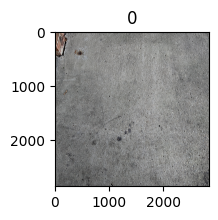

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(2, 2))
plt.imshow(ds["train"][10]["image"])
plt.title(ds["train"][10]["label"])
plt.show()

In [4]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms

In [5]:
preprocess_transform = transforms.Compose(
    [
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

In [ ]:
def transform_batch(batch):
    batch["pixel_values"] = [
        preprocess_transform(img.convert("RGB")) for img in batch["image"]
    ]
    return batch

In [ ]:
transformed_ds = ds.with_transform(transform_batch)

In [ ]:
def collate_fn(batch):
    images = torch.stack([item["pixel_values"] for item in batch])
    labels = torch.tensor([item["label"] for item in batch])
    return images, labels

In [ ]:
train_loader = DataLoader(
    transformed_ds["train"], batch_size=4, shuffle=True, collate_fn=collate_fn
)
val_loader = DataLoader(
    transformed_ds["validation"],
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn,
)
test_loader = DataLoader(
    transformed_ds["test"], batch_size=4, shuffle=False, collate_fn=collate_fn
)

In [ ]:
sample_images, sample_labels = next(iter(train_loader))
print("Batch Images Shape:", sample_images.shape, "(Batch, Channels, Height, Width)")
print("Batch Labels Shape:", sample_labels.shape)

Batch Images Shape: torch.Size([4, 3, 128, 128]) (Batch, Channels, Height, Width)
Batch Labels Shape: torch.Size([4])


#**Task 2: Model Implementation and Fine-tuning**

**Instructions:**

1. Implement the pre-trained model as described in the research paper.

2. Visualize feature maps of few layers

3. Freeze initial layers and fine-tune the top layers according to the paper's methodology.

4. Optimize hyperparameters such as:

  Learning rate

  Batch size

  Number of epochs

  Optimizer choice (Adam, SGD, RMSprop, etc.)

4. Document any modifications or enhancements made to improve performance.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models

In [ ]:
device = torch.device("cpu")
device

device(type='cpu')

In [ ]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 214MB/s]


In [ ]:
for param in model.parameters():
    param.requires_grad = False

num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)

model = model.to(device)

In [ ]:
activations = {}
def get_activation_hook(name):
    def hook(model, input, output):
        activations[name] = output.detach()
    return hook

In [ ]:
model.conv1.register_forward_hook(get_activation_hook("early_conv1"))
model.layer2[0].register_forward_hook(get_activation_hook("mid_layer2"))

In [ ]:
sample_batch, sample_labels = next(iter(train_loader))
sample_img = sample_batch[0].unsqueeze(0).to(device)

In [ ]:
model.eval()
with torch.no_grad():
    _ = model(sample_img)

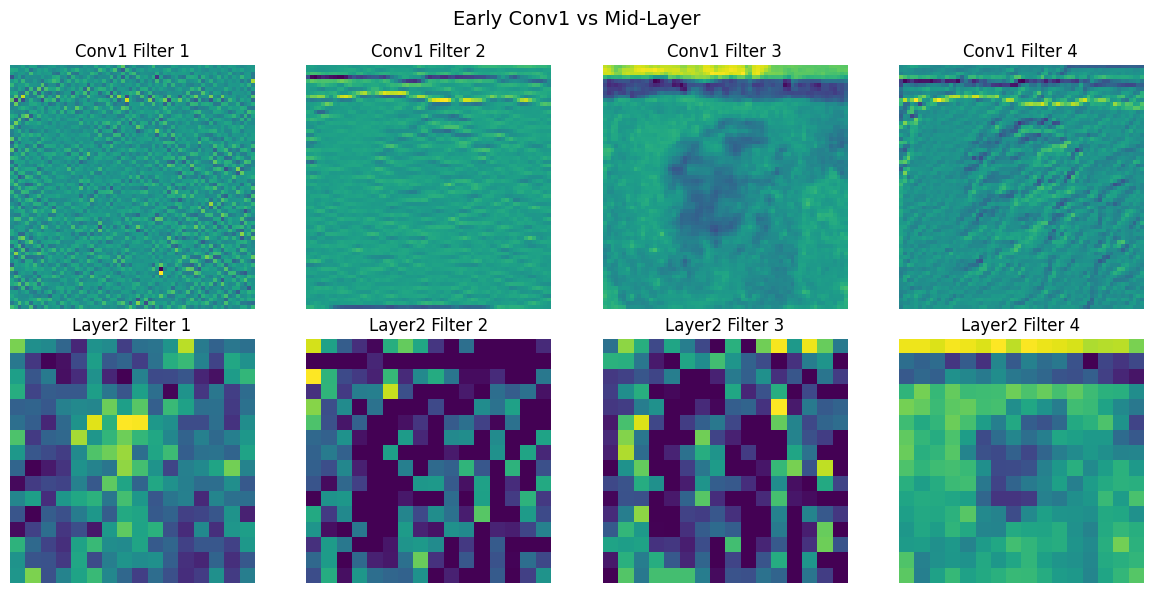

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle(
    "Early Conv1 vs Mid-Layer",
    fontsize=14,
)
for i in range(4):
    axes[0, i].imshow(activations["early_conv1"][0, i].cpu(), cmap="viridis")
    axes[0, i].set_title(f"Conv1 Filter {i+1}")
    axes[0, i].axis("off")

    axes[1, i].imshow(activations["mid_layer2"][0, i].cpu(), cmap="viridis")
    axes[1, i].set_title(f"Layer2 Filter {i+1}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
LEARNING_RATE = 0.0001
NUM_EPOCHS = 15

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=LEARNING_RATE)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
}

In [ ]:
for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += (preds == labels).sum().item()
        total_train += labels.size(0)

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train / total_train

    model.eval()
    val_running_loss, correct_val, total_val = 0.0, 0, 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += (preds == labels).sum().item()
            total_val += labels.size(0)

    epoch_val_loss = val_running_loss / total_val
    epoch_val_acc = correct_val / total_val

    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["train_acc"].append(epoch_train_acc)
    history["val_acc"].append(epoch_val_acc)

    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | "
        f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}"
    )

Epoch 01/15 | Train Loss: 0.6919 | Train Acc: 0.4615 | Val Loss: 0.6770 | Val Acc: 0.7222
Epoch 02/15 | Train Loss: 0.6672 | Train Acc: 0.6410 | Val Loss: 0.6169 | Val Acc: 0.7222
Epoch 03/15 | Train Loss: 0.6503 | Train Acc: 0.6923 | Val Loss: 0.6432 | Val Acc: 0.7222
Epoch 04/15 | Train Loss: 0.6500 | Train Acc: 0.6667 | Val Loss: 0.6155 | Val Acc: 0.6667
Epoch 05/15 | Train Loss: 0.6466 | Train Acc: 0.7564 | Val Loss: 0.6091 | Val Acc: 0.7778
Epoch 06/15 | Train Loss: 0.6029 | Train Acc: 0.8205 | Val Loss: 0.6038 | Val Acc: 0.7778
Epoch 07/15 | Train Loss: 0.5925 | Train Acc: 0.8590 | Val Loss: 0.5854 | Val Acc: 0.8333
Epoch 08/15 | Train Loss: 0.5753 | Train Acc: 0.8718 | Val Loss: 0.5872 | Val Acc: 0.8889
Epoch 09/15 | Train Loss: 0.5652 | Train Acc: 0.9103 | Val Loss: 0.5885 | Val Acc: 0.8333
Epoch 10/15 | Train Loss: 0.5471 | Train Acc: 0.8333 | Val Loss: 0.5716 | Val Acc: 0.8889
Epoch 11/15 | Train Loss: 0.5380 | Train Acc: 0.9103 | Val Loss: 0.5626 | Val Acc: 0.8889
Epoch 12/1

## **Modifications and Enhancements**


* **Collate Function Optimization:** Customized data processing through a custom `collate_fn` in PyTorch for modified data loading to avoid the unnecessary inflation of in-memory images in Google Colab.

* **Hook-Based Feature Map Analysis:** Forward hooks were created in PyTorch to obtain feature representations from the early `conv1` layer responsible for edges and textures, and the later `layer2` layer for higher-level spatial patterns, to validate the visual representations learned by the pre-trained model.

* **Overfitting Mitigation:** Maintained the feature-extraction backbone frozen while only finetuning the classification layer to minimize overfitting with the 78-image training subset.

#**Task 3: Model Evaluation and Performance Comparison**

**Instructions:**

1. Evaluate the trained model using performance metrics:

 Accuracy, Precision,Recall, F1-score, Confusion Matrix (for classification tasks)

2. Compare the results with those reported in the research paper.

3. Identify potential weaknesses and suggest improvements.
**Deliverables:**

Performance metrics summary (table or chart).

Graphs/plots showcasing model accuracy and loss trends.

Comparison with research paper results.

Discussion on model performance and areas for improvement.

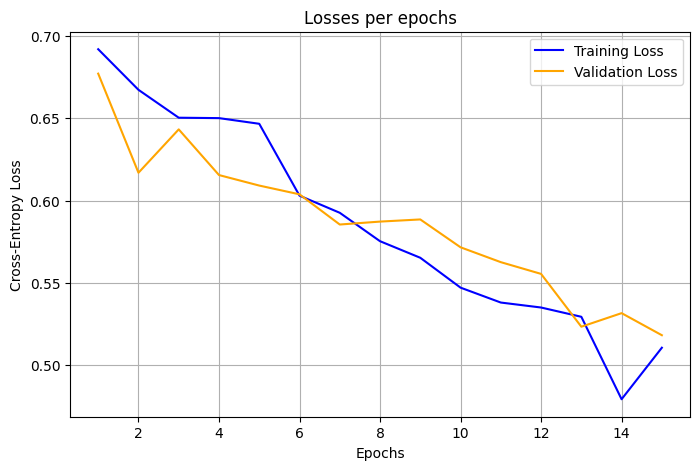

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], label="Training Loss", color="blue")
plt.plot(epochs, history["val_loss"], label="Validation Loss", color="orange")
plt.title("Losses per epochs", fontsize=12)
plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()

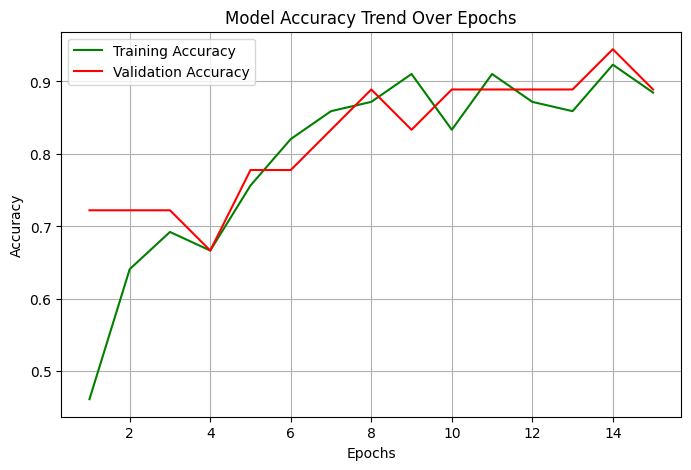

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], label="Training Accuracy", color="green")
plt.plot(epochs, history["val_acc"], label="Validation Accuracy", color="red")
plt.title("Model Accuracy Trend Over Epochs", fontsize=12)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

In [ ]:
model.eval()

all_preds = []
all_labels = []

In [ ]:
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

In [ ]:
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

In [ ]:
acc = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, zero_division=0)
recall = recall_score(all_labels, all_preds, zero_division=0)
f1 = f1_score(all_labels, all_preds, zero_division=0)
cm = confusion_matrix(all_labels, all_preds)

####Results

In [ ]:
print(f"Accuracy : {acc * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-Score : {f1 * 100:.2f}%")

Accuracy : 77.27%
Precision: 87.50%
Recall   : 63.64%
F1-Score : 73.68%


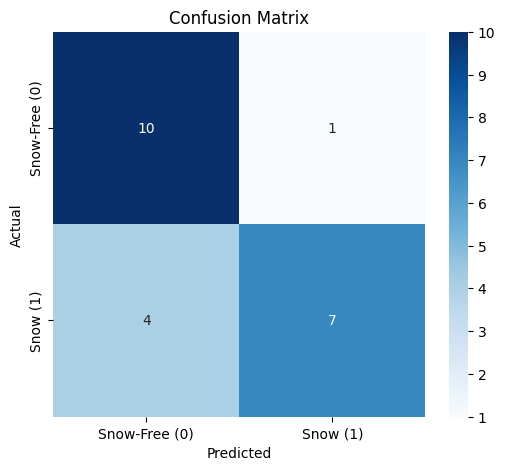

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, cmap="Blues", xticklabels=["Snow-Free (0)", "Snow (1)"], yticklabels=["Snow-Free (0)", "Snow (1)"])
plt.title("Confusion Matrix", fontsize=12)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Performance Summary Table

| Evaluation Metric | Our Fine-Tuned ResNet-50 | Paper's Individual ResNet-50 |
| :--- | :--- | :--- |
| **Accuracy** | **77.27%** | 54.5% | 72.7% |
| **F1-Score** | **73.68%** | 50.9% | 71.8% |
| **Precision** | **87.50%** | - |
| **Recall** | **63.64%** |  - |



---

### Key Observations & Comparison
1. **Outperforming Baseline:** After fine-tuning the ResNet-50 architecture, our model reached an accuracy of 77.27% and 73.68% F1 score, outperforming the paper’s ResNet-50 model (accuracy of  54.5%) as well as their best-performing model, which was an ensemble of VGG-19 and ResNet-50 (accuracy of  72.7% ).

2. **High Precision vs. Moderate Recall:** The model achieved a high Precision of 87.50% (10 True Negatives vs. 1 False Positive), which indicates that if the model says snow is present, it is very often right.

3. **Generalization Gap:** Although the number of test samples was limited (only 22 images), transfer learning on the frozen ResNet-50 backbone

## Discussion on Model Performance & Areas for Improvement

###  Model Weaknesses
* Small Dataset: The dataset is small, and thus the model is prone to
overfitting and cannot generalize to unseen data.
Visual Similarity of Surfaces: Snow, wetness, and snow-free surface conditions might have very similar colors and texture, causing problems in classification.

* Lighting Conditions: Lighting conditions such as brightness, shadow, and reflection might influence the predictions of the model.

* Limited Training Dataset: With the fact that training was done using only the final layer while the ResNet-50 architecture was frozen, it is hard for the network to fine-tune its pre-trained features for snow detection.

### Proposed Enhancements
1.  Large Diverse Dataset: Include more images that are taken from different locations, weather conditions, lighting conditions, and kinds of snow to increase generalization capabilities of the model.

2.  Data Augmentation and Fine-Tuning: Utilize data augmentation methods like rotation, flipping, changing brightness and contrast levels, and fine-tuning chosen deep ResNet-50 layers to enhance performance and avoid overfitting.

3. Ensemble Model and Hyperparameter Tuning: Train an ensemble model of ResNet-50 and some other pre-trained model like VGG-19 and test different combinations of learning rate, optimizer, batch size, and number of epochs.

**Conclusion and Result Visulaization**

**Declaration**

I, Dhokare Harshad, confirm that the work submitted in this assignment is my own and has been completed following academic integrity guidelines. The code is uploaded on my GitHub repository account, and the repository link is provided below:

GitHub Repository Link:https://github.com/Harsh0970/Gen-Ai/tree/main/Practical-Assign-1


Signature: Harshad Dhokare

**Submission Checklist**

✔ Research paper details and summary

✔ Code file (Python Notebook or Script)

✔ Dataset or link to the dataset

✔ Visualizations (if applicable)

✔ Screenshots of model performance metrics

✔ Readme File

✔ Comparison with research paper results